<a href="https://colab.research.google.com/github/abdealimak/ML-CW/blob/main/LinearRegression_House_Price_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment: California Housing Price Prediction using Linear Regression

This notebook demonstrates a complete machine learning pipeline to predict house prices using the **California Housing Dataset** and a **Linear Regression** model from `scikit-learn`.

In [52]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("--- Step 1: Libraries Imported successfully ---")

--- Step 1: Libraries Imported successfully ---


## 1. Load and Explore the Dataset

First, we load the California Housing dataset directly from `scikit-learn` and convert it into a Pandas DataFrame to inspect its features and target variables.

In [53]:
# Load the raw dataset
california = fetch_california_housing(as_frame=True)
df = california.frame

print("--- Step 2: California Housing Dataset Loaded ---")
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns.\n")

print("Feature Columns:")
print(california.feature_names)
print("\nTarget Column:")
print(california.target_names)

print("\nFirst 5 rows of the dataset:")
display(df.head())

--- Step 2: California Housing Dataset Loaded ---
Dataset Shape: 20640 rows and 9 columns.

Feature Columns:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target Column:
['MedHouseVal']

First 5 rows of the dataset:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 2. Descriptive Statistics

To better understand our data, we display basic statistical details like mean, standard deviation, and percentiles for each feature.

In [54]:
print("--- Step 3: Statistical Summary --- ")
display(df.describe())

--- Step 3: Statistical Summary --- 


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## 3. Data Splitting

We separate the dataset into independent variables (features, `X`) and the dependent variable (target, `y`). Then we split them into Training (80%) and Testing (20%) sets.

In [55]:
X = california.data
y = california.target

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("--- Step 4: Data Successfully Split ---")
print(f"Training set shape (Features): {X_train.shape}")
print(f"Testing set shape (Features): {X_test.shape}")

--- Step 4: Data Successfully Split ---
Training set shape (Features): (16512, 8)
Testing set shape (Features): (4128, 8)


## 4. Model Training

We initialize the `LinearRegression` model and fit (train) it on our training data.

In [56]:
model = LinearRegression()

print("--- Step 5: Training the Linear Regression Model... ---")
model.fit(X_train, y_train)
print("Model training completed.")

--- Step 5: Training the Linear Regression Model... ---
Model training completed.


## 5. Model Evaluation

We use our trained model to make predictions on the test set and evaluate its performance using key metrics: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R-squared ($R^2$).

In [57]:
from sklearn.metrics import mean_absolute_error

# Predict the target values for the test set
y_pred = model.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("--- Step 6: Model Evaluation Results ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")
print("\nModel Coefficients (Weights):\n")
for feature, coef in zip(california.feature_names, model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

--- Step 6: Model Evaluation Results ---
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
Mean Absolute Error (MAE): 0.5332
R-squared Score (R2): 0.5758

Model Coefficients (Weights):

MedInc: 0.4487
HouseAge: 0.0097
AveRooms: -0.1233
AveBedrms: 0.7831
Population: -0.0000
AveOccup: -0.0035
Latitude: -0.4198
Longitude: -0.4337
Intercept: -37.0233


In [58]:
# Predict the target values for the test set
y_pred = model.predict(X_test)

# Calculate metrics
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("--- Step 6: Model Evaluation Results ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared Score (R2): {r2:.4f}")
print("\nModel Coefficients (Weights):\n")
for feature, coef in zip(california.feature_names, model.coef_):
    print(f"{feature}: {coef:.4f}")
print(f"Intercept: {model.intercept_:.4f}")

--- Step 6: Model Evaluation Results ---
Mean Squared Error (MSE): 0.5559
Root Mean Squared Error (RMSE): 0.7456
R-squared Score (R2): 0.5758

Model Coefficients (Weights):

MedInc: 0.4487
HouseAge: 0.0097
AveRooms: -0.1233
AveBedrms: 0.7831
Population: -0.0000
AveOccup: -0.0035
Latitude: -0.4198
Longitude: -0.4337
Intercept: -37.0233


## 6. Model Evaluation with MAE

Let's add the Mean Absolute Error (MAE) metric to complete the performance analysis of our regression model.

In [59]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)
print("--- Step 7: Mean Absolute Error Calculation ---")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

--- Step 7: Mean Absolute Error Calculation ---
Mean Absolute Error (MAE): 0.5332


## 7. Model Predictions on a New Custom Dataset

Let's create a custom data point representing a new house, input it into our model, and inspect the model's predicted valuation.

In [60]:
# Define a new home with average/realistic features based on our dataset statistics
custom_house_data = {
    'MedInc': [6.5],       # Median income of 65k
    'HouseAge': [15.0],    # 15 years old
    'AveRooms': [6.0],     # Average of 6 rooms
    'AveBedrms': [1.0],    # Average of 1 bedroom
    'Population': [1200.0],# Population block of 1,200 people
    'AveOccup': [2.8],     # 2.8 average occupants
    'Latitude': [34.05],   # Los Angeles latitude
    'Longitude': [-118.24] # Los Angeles longitude
}

custom_df = pd.DataFrame(custom_house_data)

# Make prediction
custom_prediction = model.predict(custom_df)

print("--- Step 8: Predictions on Custom House Dataset ---")
display(custom_df)
print(f"\nPredicted House Value: ${custom_prediction[0] * 100000:.2f} (represented as {custom_prediction[0]:.4f} in tens of thousands)")

--- Step 8: Predictions on Custom House Dataset ---


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,6.5,15.0,6.0,1.0,1200.0,2.8,34.05,-118.24



Predicted House Value: $305757.61 (represented as 3.0576 in tens of thousands)


## 8. Visualizing Model Performance

Finally, we will visualize the model's performance by plotting actual versus predicted house values, and the importance of each feature according to our model's coefficients.

### Plot 1: Actual vs. Predicted Scatter Plot

This plot shows the relationship between the actual house values and our model's predictions. The diagonal red dashed line represents perfect predictions.

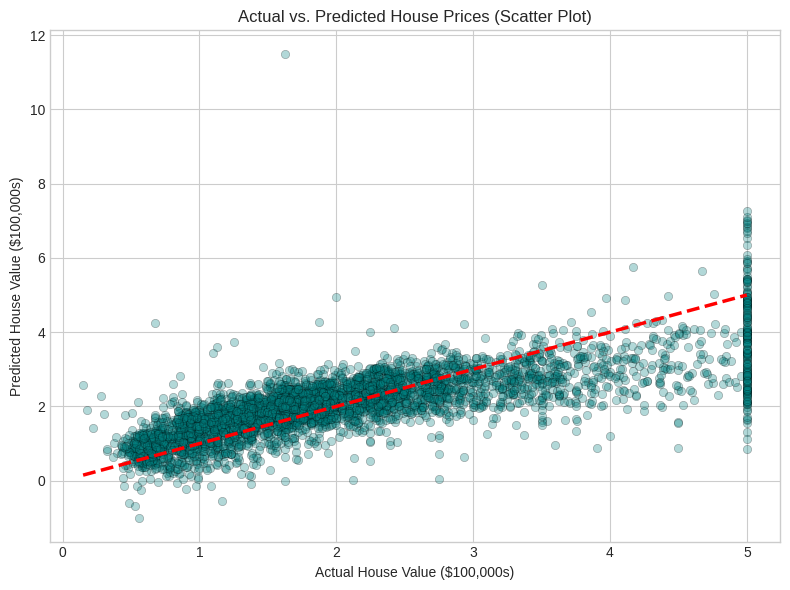

In [61]:
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-whitegrid')

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='teal', edgecolor='black', linewidth=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2.5)
plt.xlabel('Actual House Value ($100,000s)')
plt.ylabel('Predicted House Value ($100,000s)')
plt.title('Actual vs. Predicted House Prices (Scatter Plot)')
plt.tight_layout()
plt.show()

### Plot 2: Actual vs. Predicted Bar Chart (Subset Sample)

Since plotting all test points in a bar chart would be unreadable, we select a random sample of 25 test points to inspect and compare side-by-side.

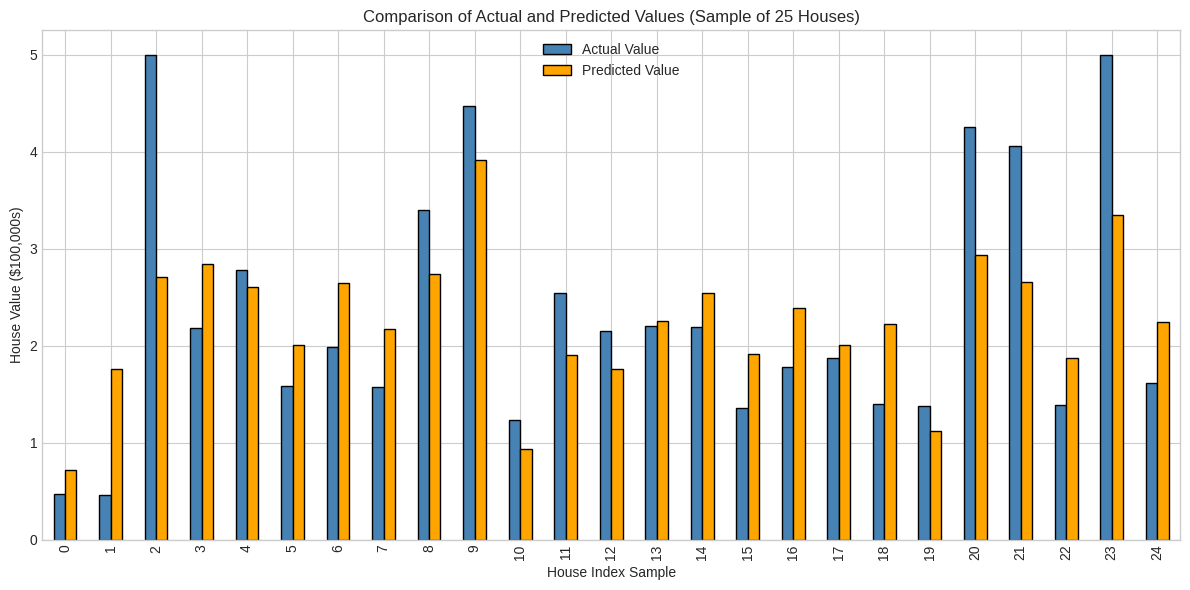

In [62]:
import pandas as pd

# Combine test values and predictions into a temporary DataFrame
comparison_df = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred}).reset_index(drop=True)

# Take a sample of 25 instances
sample_df = comparison_df.head(25)

# Plot actual vs predicted as a bar chart
sample_df.plot(kind='bar', figsize=(12, 6), color=['steelblue', 'orange'], edgecolor='black')
plt.title('Comparison of Actual and Predicted Values (Sample of 25 Houses)')
plt.xlabel('House Index Sample')
plt.ylabel('House Value ($100,000s)')
plt.legend(['Actual Value', 'Predicted Value'])
plt.tight_layout()
plt.show()

### Plot 3: Feature Importance (Model Coefficients)

This visualization shows which features have the strongest positive or negative impact on the predicted house price.

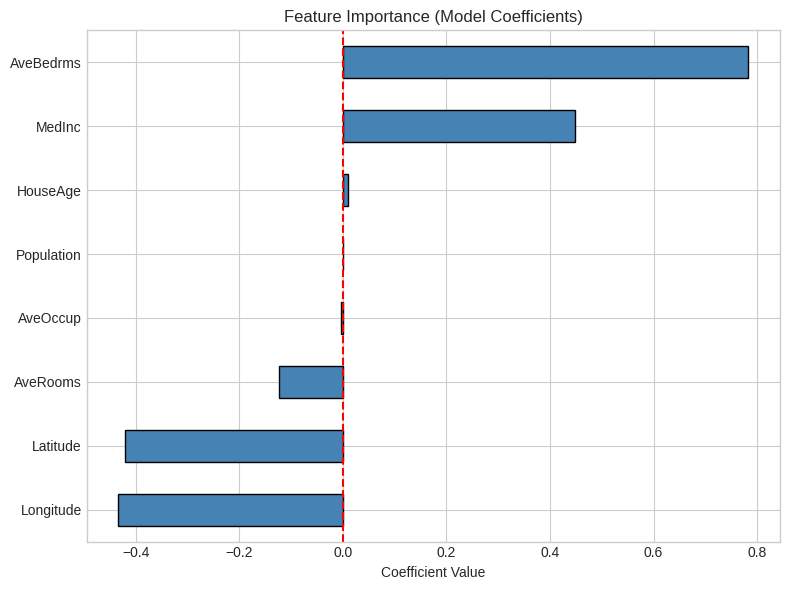

In [63]:
plt.figure(figsize=(8, 6))
coef_series = pd.Series(model.coef_, index=california.feature_names).sort_values()
coef_series.plot(kind='barh', color='steelblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='--', linewidth=1.5)
plt.xlabel('Coefficient Value')
plt.title('Feature Importance (Model Coefficients)')
plt.tight_layout()
plt.show()

## 9. Converting to a Classification Problem

To calculate classification metrics (Accuracy, Precision, Recall, F1-score, and a Confusion Matrix), we convert our continuous target variable `y` (house values) into binary classes:
- **`1` (High Value)**: House value is above the median value.
- **`0` (Low Value)**: House value is below or equal to the median value.

In [64]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import seaborn as sns

# Calculate the median of the target variable to act as a threshold
median_value = np.median(y)

# Binary conversion
y_train_class = (y_train > median_value).astype(int)
y_test_class = (y_test > median_value).astype(int)

# Scale the features for classification to ensure optimizer convergence
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("--- Step 9: Target Converted and Features Scaled successfully ---")
print(f"Median Threshold: ${median_value * 100000:.2f}")
print(f"Class Distribution in Training Set: {np.bincount(y_train_class)}")

--- Step 9: Target Converted and Features Scaled successfully ---
Median Threshold: $179700.00
Class Distribution in Training Set: [8246 8266]


## 10. Training a Classifier and Calculating Metrics

We train a `LogisticRegression` model on the transformed dataset and evaluate it using Accuracy, Precision, Recall, and F1-score.

In [65]:
# Initialize and train Logistic Regression on the SCALED features
clf = LogisticRegression(max_iter=1000, random_state=42)
clf.fit(X_train_scaled, y_train_class)

# Predict classifications on the scaled test set
y_pred_class = clf.predict(X_test_scaled)

# Calculate classification metrics
acc = accuracy_score(y_test_class, y_pred_class)
prec = precision_score(y_test_class, y_pred_class)
rec = recall_score(y_test_class, y_pred_class)
f1 = f1_score(y_test_class, y_pred_class)

print("--- Step 10: Classification Model Metrics (Scaled Data) ---")
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-Score:  {f1:.4f}")

--- Step 10: Classification Model Metrics (Scaled Data) ---
Accuracy:  0.8261
Precision: 0.8253
Recall:    0.8245
F1-Score:  0.8249


## 11. Visualizing the Confusion Matrix

Now we plot and display the confusion matrix to see the model's rate of true positives, true negatives, false positives, and false negatives.

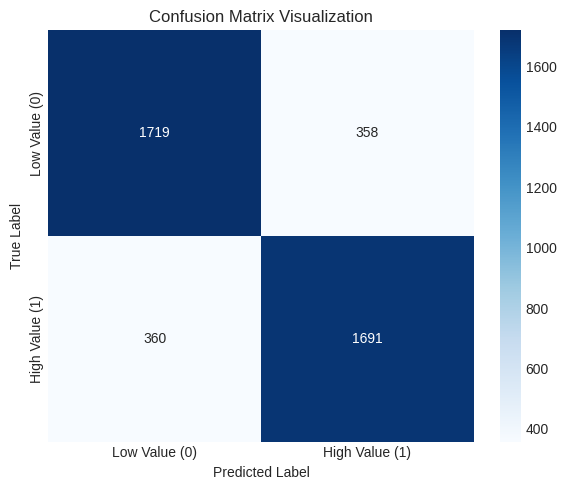

In [66]:
cm = confusion_matrix(y_test_class, y_pred_class)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Low Value (0)', 'High Value (1)'],
            yticklabels=['Low Value (0)', 'High Value (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix Visualization')
plt.tight_layout()
plt.show()